# Part 3: Data Mining Techniques for HSL Bus Reliability

Project focus: HSL bus route reliability using static GTFS schedules and GTFS-RT live data.

This notebook narrows the earlier HSL dataset from the full multimodal feed to bus services only. The dashboard still stores raw GTFS and GTFS-RT data for reproducibility, but the modelling layer filters to HSL bus route families `701`, `702`, and `704`.

Techniques implemented are:

1. `KMeans` clustering to group route-stop windows with similar reliability and realtime-coverage patterns.
2. `DBSCAN` clustering to identify spatial hotspots and dense reliability problem areas.
3. `Isolation Forest` and `LOF` anomaly detection to flag unusual route-stop-hour windows.

Predictive modelling is left as future work because the course requires at least two techniques, and the available GTFS-RT delay history is still limited separately as there is no saved data available in the forum.

<!-- BUS_ONLY_MODEL_SNAPSHOT -->
# Saved Bus-Only Model Snapshot

Generated from the running local API on `2026-04-27T19:24:24Z`.

This notebook is scoped to HSL bus reliability only using GTFS route types `701`, `702`, and `704`. Raw GTFS/GTFS-RT ingestion remains available for reproducibility, but modelling, interpretation, dashboard layers, clusters, and anomalies are bus-focused.

## Current API Evidence

| Evidence item | Value |
|---|---:|
| Latest vehicle-position poll | 2026-04-27T19:23:53.804494Z |
| Latest trip-update poll | 2026-04-27T19:23:53.835396Z |
| Stored vehicle positions | 1,839,575 |
| Stored trip updates | 2,552,955 |
| Schedule-adherence events | 336,717 |
| Model feature windows | 312,859 |
| Latest feature bucket | 2026-04-27T19:00:00+00:00 |
| Cluster assignments | 6,000 |
| DBSCAN model hotspots | 106 |
| Active anomaly windows | 285 |
| Anomaly scored windows | 5,000 |
| Average prediction coverage | 96.6% |

## Selected Models From Latest Runs

| Technique | Selected parameters | Key evaluation |
|---|---|---|
| KMeans | `{"k":2,"n_init":20}` | silhouette=0.401, Davies-Bouldin=1.175, Calinski-Harabasz=2417.923 |
| DBSCAN | `{"eps":0.8,"min_samples":20}` | silhouette=0.554, noise share=0.389, clusters=n/a |
| Isolation Forest | `{"max_samples":512,"n_estimators":500,"contamination":0.01}` | Precision@K=0.940, recall=0.076, false-alarm share=0.001 |
| Local Outlier Factor | `{"n_neighbors":50,"contamination":0.05}` | Precision@K=0.444, recall=0.178, false-alarm share=0.028 |

We use KMeans to helps us answer: which bus stops/routes behave similarly? For example, one cluster may represent reliable service, another may represent delay-prone service, and another may represent low real-time coverage. This is useful for transport planners because they do not need to inspect thousands of stops manually. The model gives a high-level structure of the network.

Where as DBSCAN helps answer: where are the reliability hotspots in the bus network? This is more practical for urban mobility planning than only saying “Route 560 has delays.” DBSCAN can point to specific stop areas or corridors that deserve investigation.

Where as Isolation Forest helps answer: which bus reliability situations look abnormal today? For example, a stop that normally has good prediction coverage but suddenly has poor coverage, or a route window with unusually high delay, can be flagged for attention.

and finally Local Outlier Factor helps answer: which bus windows are unusual compared with similar nearby behavior? This makes it a good second anomaly model to compare with Isolation Forest.

so all these methods helps us to analyze HSL bus reliability. KMeans groups similar route-stop-hour reliability patterns, DBSCAN identifies hotspot areas, Isolation Forest detects globally unusual reliability windows, and LOF detects locally unusual behavior. These techniques help convert raw GTFS and GTFS-RT data into operational insights for public transport planning.

## Dashboard/API Evidence Used

- Dashboard: `http://localhost:5173/`
- Model status API: `http://localhost:8000/api/v1/models/status`
- Cluster layer API: `http://localhost:8000/api/v1/models/clusters`
- Anomaly layer API: `http://localhost:8000/api/v1/models/anomalies/live`

Saved machine-readable evidence from earlier captures remains in:

- `../reports/snapshots/bus_model_snapshot_latest.json`
- `../reports/snapshots/bus_model_snapshot_compact.json`
- `../reports/history_exports/` for CSV exports of recent bus GTFS-RT/model history.

Dashboard screenshot evidence:

![HSL bus dashboard live view](../reports/screenshots/hsl-bus-dashboard-live.png)

![alt text](image.png)


## 1. Why Bus-Only Analysis?

HSL GTFS contains several public transport modes. For this project, bus-only analysis gives a cleaner and more explainable urban mobility problem:

- buses operate on the street network and are more exposed to congestion and operational variability;
- GTFS-RT vehicle positions are meaningful for live bus movement on a map;
- bus stop, route, and hourly features can be connected directly to schedule adherence;
- focusing on one mode avoids mixing metro, tram, rail, and bus behavior in the same model.

This supports the course objective: use real transportation data to identify patterns, detect anomalies, and evaluate public transport efficiency.

In [1]:
from __future__ import annotations

import json
import urllib.error
import urllib.request

import pandas as pd
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value)

API_BASE = "http://localhost:8000/api/v1"
BUS_ROUTE_TYPES = {701, 702, 704}


def get_json(path: str):
    """Read dashboard/API evidence from the running local FastAPI backend."""
    url = f"{API_BASE}{path}"
    try:
        with urllib.request.urlopen(url, timeout=30) as response:
            return json.loads(response.read().decode("utf-8"))
    except (urllib.error.URLError, TimeoutError, json.JSONDecodeError) as exc:
        print(f"API data unavailable for {path}: {exc}")
        return None


def ensure_dict(value):
    """The API can return JSONB columns as strings, so normalize them before analysis."""
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        try:
            parsed = json.loads(value)
        except json.JSONDecodeError:
            return {}
        return parsed if isinstance(parsed, dict) else {}
    return {}


def normalize_run(run: dict) -> dict:
    run = dict(run)
    run["selected_params"] = ensure_dict(run.get("selected_params"))
    run["metrics"] = ensure_dict(run.get("metrics"))
    return run


def feature_collection_to_frame(payload):
    if not payload or not payload.get("features"):
        return pd.DataFrame()
    rows = []
    for feature in payload["features"]:
        props = dict(feature.get("properties", {}))
        coords = feature.get("geometry", {}).get("coordinates", [None, None])
        props["longitude"] = coords[0]
        props["latitude"] = coords[1]
        rows.append(props)
    return pd.DataFrame(rows)


def optional_line_plot(df, x, y, title):
    """Plot when matplotlib is available; otherwise the tables below remain sufficient."""
    try:
        import matplotlib.pyplot as plt
    except ImportError:
        print("Matplotlib is not installed in this kernel; using tables only.")
        return
    if df.empty or x not in df.columns or y not in df.columns:
        return
    ax = df.plot(x=x, y=y, marker="o", title=title, figsize=(7, 3), grid=True)
    ax.set_ylabel(y)
    plt.show()


## 2. Load Bus-Focused Model Outputs

The dashboard backend computes bus-only features and model outputs. This notebook reads those outputs through the API so the notebook, dashboard, and report all explain the same analysis.

In [2]:
status = get_json("/models/status") or {}
ingestion = get_json("/ingestion/status") or {}
routes = get_json("/routes") or []
clusters_payload = get_json("/models/clusters?limit=2000")
anomalies_payload = get_json("/models/anomalies/live?hours=48&limit=1000")
runs_payload = get_json("/models/runs?limit=20") or {"runs": []}

clusters_df = feature_collection_to_frame(clusters_payload)
anomalies_df = feature_collection_to_frame(anomalies_payload)
routes_df = pd.DataFrame(routes)
runs = [normalize_run(run) for run in runs_payload.get("runs", [])]

print("Model status:")
print(json.dumps(status, indent=2))
print("\nIngestion status:")
print(json.dumps({
    "latest_vehicle_position_at": ingestion.get("latest_vehicle_position_at"),
    "latest_trip_update_at": ingestion.get("latest_trip_update_at"),
    "vehicle_positions_count": ingestion.get("vehicle_positions_count"),
    "trip_updates_count": ingestion.get("trip_updates_count"),
    "adherence_events_count": ingestion.get("adherence_events_count"),
}, indent=2))
print("\nCluster rows loaded:", len(clusters_df))
print("Anomaly rows loaded:", len(anomalies_df))
print("Routes returned:", len(routes_df))

if not routes_df.empty:
    print("Route types in route API output:", sorted(routes_df["route_type"].dropna().unique().tolist()))


Model status:
{
  "feature_windows": 312859,
  "latest_feature_bucket": "2026-04-27T19:00:00+00:00",
  "cluster_assignments": 6000,
  "hotspot_count": 106,
  "active_anomalies": 285,
  "anomaly_scored_windows": 5000,
  "latest_anomaly_bucket": "2026-04-27T19:00:00+00:00",
  "avg_prediction_coverage": 0.9662151301401224,
  "latest_cluster_run": "2026-04-27T19:10:42.401927+00:00",
  "latest_anomaly_run": "2026-04-27T19:18:16.441466+00:00"
}

Ingestion status:
{
  "latest_vehicle_position_at": "2026-04-27T19:50:10.338066Z",
  "latest_trip_update_at": "2026-04-27T19:50:10.368124Z",
  "vehicle_positions_count": 1863742,
  "trip_updates_count": 2580572,
  "adherence_events_count": 336717
}

Cluster rows loaded: 2000
Anomaly rows loaded: 1000
Routes returned: 239
Route types in route API output: [701, 702, 704]


## 2.1 Bus-Only Validation

Before modelling, we verify that the notebook is not mixing modes. The accepted HSL bus route types are:

- `701`: regional bus
- `702`: express bus
- `704`: local bus

This validation is important because mixing bus, metro, rail, tram, and ferry behavior would make the clusters harder to explain and weaker for this Project Scope.


In [3]:
def route_type_summary(df, label):
    if df.empty or "route_type" not in df.columns:
        return pd.DataFrame({"dataset": [label], "route_type": ["none"], "count": [0]})
    summary = (
        df.groupby("route_type", dropna=False)
        .size()
        .reset_index(name="count")
        .assign(dataset=label)
        [["dataset", "route_type", "count"]]
    )
    return summary

bus_checks = pd.concat(
    [
        route_type_summary(routes_df, "route metrics"),
        route_type_summary(clusters_df, "cluster layer"),
        route_type_summary(anomalies_df, "anomaly layer"),
    ],
    ignore_index=True,
)
display(bus_checks)

for label, df in [("routes", routes_df), ("clusters", clusters_df), ("anomalies", anomalies_df)]:
    if not df.empty and "route_type" in df.columns:
        non_bus = sorted(set(df["route_type"].dropna().astype(int)) - BUS_ROUTE_TYPES)
        assert not non_bus, f"{label} contains non-bus route types: {non_bus}"

print("Bus-only validation passed: all loaded route/model rows are route_type 701, 702, or 704.")


,dataset,route_type,count
0,route metrics,701,196
1,route metrics,702,13
2,route metrics,704,30
3,cluster layer,701,1501
4,cluster layer,702,499
5,anomaly layer,701,920
6,anomaly layer,702,77
7,anomaly layer,704,3


Bus-only validation passed: all loaded route/model rows are route_type 701, 702, or 704.


## 3. Feature Engineering Used by the Models

Each model row represents a bus route-stop-hour window. The important features are:

- delay features: mean delay, median delay, 95th percentile absolute delay, delay standard deviation;
- schedule adherence features: on-time ratio, late ratio, early ratio;
- realtime quality features: prediction coverage, vehicle observation count, feed age;
- temporal features: hour of day, day of week, weekend flag;
- spatial features: stop latitude and longitude for map interpretation.

Because the stored realtime history is limited, coverage and freshness are especially important. They show where the realtime comparison is strong or weak.

In [4]:

if clusters_df.empty:
    print("No cluster data available. Start Docker and run model recomputation from the dashboard/API.")
else:
    display_columns = [
        "route_id", "route_short_name", "stop_id", "stop_name", "reliability_label",
        "kmeans_cluster", "dbscan_cluster", "dbscan_is_hotspot", "mean_delay_minutes",
        "p95_abs_delay_minutes", "prediction_coverage_ratio", "sample_count",
    ]
    display(clusters_df[[col for col in display_columns if col in clusters_df.columns]].head(10))


,route_id,route_short_name,stop_id,stop_name,reliability_label,kmeans_cluster,dbscan_cluster,dbscan_is_hotspot,mean_delay_minutes,p95_abs_delay_minutes,prediction_coverage_ratio,sample_count
0,1052,52,1332172,Esikoisentie,delay_hotspot,1,1,True,0.49,2.31,0.982,26
1,1052,52,1331104,Kaustisentie,delay_hotspot,1,1,True,0.56,2.29,0.982,26
2,1056,56,1283132,Vaskisepäntie,delay_hotspot,1,1,True,0.31,2.28,0.985,26
3,2118,118,2613215,Kirstin koulu,delay_hotspot,1,1,True,0.91,2.28,0.965,26
4,1052,52,1334174,Kuopuksentie,delay_hotspot,1,1,True,0.42,2.27,0.985,26
5,1052,52,1332170,Perhekunnantie,delay_hotspot,1,1,True,0.43,2.26,0.986,26
6,2549,549,3170223,Valkonauhantie,delay_hotspot,1,1,True,0.72,2.24,0.968,26
7,2549,549,3170225,Työväen Akatemia,delay_hotspot,1,1,True,0.69,2.23,0.979,26
8,1052,52,1331165,Trumpettitie,delay_hotspot,1,1,True,0.47,2.22,0.990,26
9,1052,52,1334183,Vanhempientie,delay_hotspot,1,1,True,0.36,2.22,0.985,26


## 4. Technique A: KMeans Clustering

`KMeans` groups route-stop windows into reliability profiles. It is suitable here because the features are numeric and standardized in the backend. The model is tuned over different values of `k`, and the selected result is based on clustering metrics plus interpretability.

Selected KMeans parameters: {'k': 2, 'n_init': 20}
Interpretation: silhouette higher is better, Davies-Bouldin lower is better, Calinski-Harabasz higher is better.


,k,silhouette,davies_bouldin,calinski_harabasz
0,2,0.400902,1.175193,2417.922886
1,3,0.378381,1.110645,2552.414944
2,4,0.328804,1.076218,2526.504631
3,5,0.322647,1.161869,2278.656977
4,6,0.313666,1.233791,2108.552291
5,7,0.324780,1.161751,2013.906267
6,8,0.301022,1.188122,1951.342132
7,9,0.282105,1.168883,1895.739929
8,10,0.264388,1.159450,1855.618259


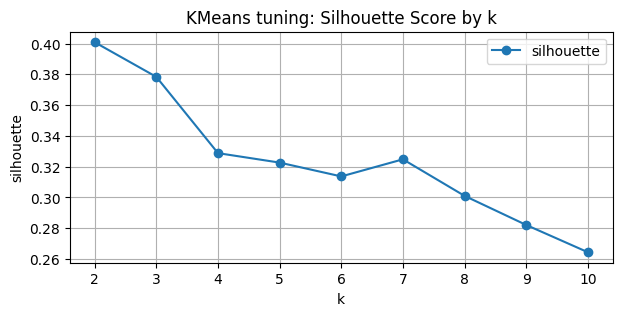

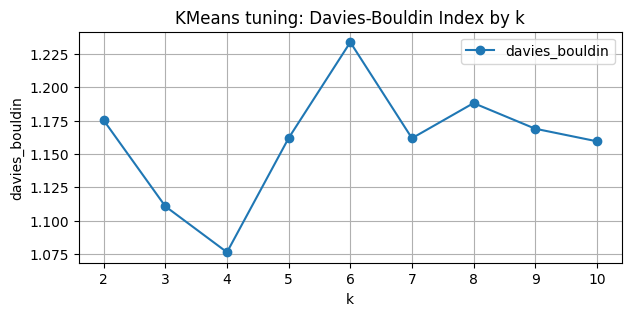

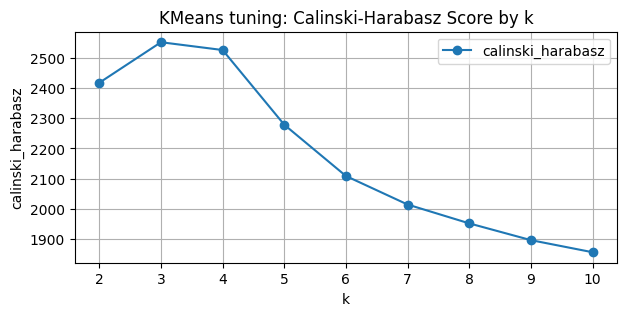

In [9]:
cluster_runs = [run for run in runs if run.get("model_family") == "clustering" and run.get("status") == "completed"]
latest_cluster_run = cluster_runs[0] if cluster_runs else None

if latest_cluster_run:
    kmeans_trials = latest_cluster_run.get("metrics", {}).get("kmeans_trials", [])
    kmeans_df = pd.DataFrame(kmeans_trials)
    selected_kmeans = latest_cluster_run.get("selected_params", {}).get("kmeans")
    print("Selected KMeans parameters:", selected_kmeans)
    print("Interpretation: silhouette higher is better, Davies-Bouldin lower is better, Calinski-Harabasz higher is better.")
    if not kmeans_df.empty:
        metric_cols = ["k", "silhouette", "davies_bouldin", "calinski_harabasz"]
        display(kmeans_df[metric_cols])
        optional_line_plot(kmeans_df, "k", "silhouette", "KMeans tuning: Silhouette Score by k")
        optional_line_plot(kmeans_df, "k", "davies_bouldin", "KMeans tuning: Davies-Bouldin Index by k")
        optional_line_plot(kmeans_df, "k", "calinski_harabasz", "KMeans tuning: Calinski-Harabasz Score by k")
else:
    print("No completed clustering run found yet.")


## 5. Technique A: DBSCAN Hotspot Discovery

`DBSCAN` is used because mobility reliability problems are often spatially concentrated. Unlike KMeans, DBSCAN can identify dense groups and mark noise points. In this project, DBSCAN helps identify bus stop areas that deserve inspection on the map.

Selected DBSCAN parameters: {'eps': 0.8, 'min_samples': 20}


,eps,min_samples,cluster_count,noise_share,silhouette,davies_bouldin
11,0.8,20,2,0.388833,0.553607,0.620495
3,0.4,20,2,0.978333,0.372485,0.885780
7,0.6,20,2,0.634000,0.278380,0.739592
10,0.8,15,6,0.330500,0.268874,0.750794
15,1.0,20,6,0.205833,0.242085,0.804892
24,2.0,5,4,0.009167,0.207909,1.626493
18,1.3,15,5,0.077333,0.203909,1.192123
14,1.0,15,6,0.170667,0.193511,0.920417
19,1.3,20,5,0.091833,0.192693,1.088403
23,1.6,20,5,0.048167,0.190396,1.229388


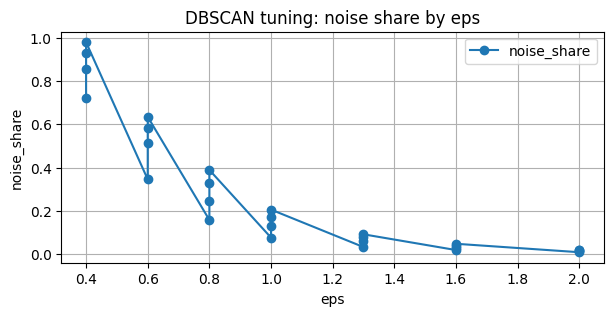

,label,count
0,reliable,848
1,delay_hotspot,724
2,watch,227
3,low_realtime_coverage,201


Loaded cluster layer contains 106 DBSCAN model hotspot points.


In [10]:
if latest_cluster_run:
    dbscan_trials = latest_cluster_run.get("metrics", {}).get("dbscan_trials", [])
    dbscan_df = pd.DataFrame(dbscan_trials)
    selected_dbscan = latest_cluster_run.get("selected_params", {}).get("dbscan")
    print("Selected DBSCAN parameters:", selected_dbscan)
    if not dbscan_df.empty:
        display(
            dbscan_df.sort_values(by=["silhouette"], ascending=False, na_position="last")
            [["eps", "min_samples", "cluster_count", "noise_share", "silhouette", "davies_bouldin"]]
            .head(10)
        )
        optional_line_plot(
            dbscan_df.sort_values(["eps", "min_samples"]),
            "eps",
            "noise_share",
            "DBSCAN tuning: noise share by eps",
        )

if not clusters_df.empty and "reliability_label" in clusters_df.columns:
    label_counts = clusters_df["reliability_label"].value_counts().rename_axis("label").reset_index(name="count")
    display(label_counts)

    hotspot_count = int(clusters_df.get("dbscan_is_hotspot", pd.Series(dtype=bool)).fillna(False).sum())
    print(f"Loaded cluster layer contains {hotspot_count} DBSCAN model hotspot points.")


## 6. Technique B: Anomaly Detection

Two anomaly detection models are used:

- `Isolation Forest`: identifies unusual points by how easily they can be isolated from the rest of the feature space.
- `LOF`: identifies local outliers by comparing each point to nearby points.

Pseudo-labels are used for evaluation because there is no official labelled anomaly dataset. Pseudo-labels include coverage dropouts, stale feed windows, and unusual realtime behavior.

Selected Isolation Forest: {'max_samples': 512, 'n_estimators': 500, 'contamination': 0.01}


,n_estimators,max_samples,contamination,precision_at_k,recall,f1_proxy,false_alarm_share
21,500,512,0.01,0.94,0.075563,0.139881,0.0006
0,100,256,0.01,0.92,0.073955,0.136905,0.0008
3,100,512,0.01,0.92,0.073955,0.136905,0.0008
6,100,auto,0.01,0.92,0.073955,0.136905,0.0008
9,200,256,0.01,0.92,0.073955,0.136905,0.0008
15,200,auto,0.01,0.92,0.073955,0.136905,0.0008
18,500,256,0.01,0.92,0.073955,0.136905,0.0008
24,500,auto,0.01,0.92,0.073955,0.136905,0.0008
12,200,512,0.01,0.90,0.072347,0.133929,0.0010
22,500,512,0.02,0.78,0.125402,0.216066,0.0044


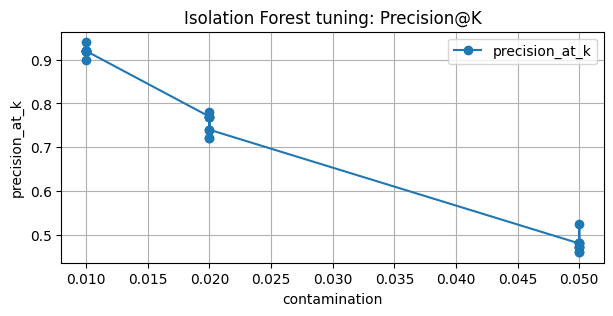

Selected LOF: {'n_neighbors': 50, 'contamination': 0.05}


,n_neighbors,contamination,precision_at_k,recall,f1_proxy,false_alarm_share
9,50,0.01,0.480,0.038585,0.071429,0.0052
11,50,0.05,0.444,0.178457,0.254587,0.0278
7,35,0.02,0.370,0.059486,0.102493,0.0126
10,50,0.02,0.370,0.059486,0.102493,0.0126
8,35,0.05,0.340,0.136656,0.194954,0.0330
6,35,0.01,0.280,0.022508,0.041667,0.0072
5,20,0.05,0.244,0.098071,0.139908,0.0378
3,20,0.01,0.200,0.016077,0.029762,0.0080
2,10,0.05,0.180,0.072347,0.103211,0.0410
4,20,0.02,0.170,0.027331,0.047091,0.0166


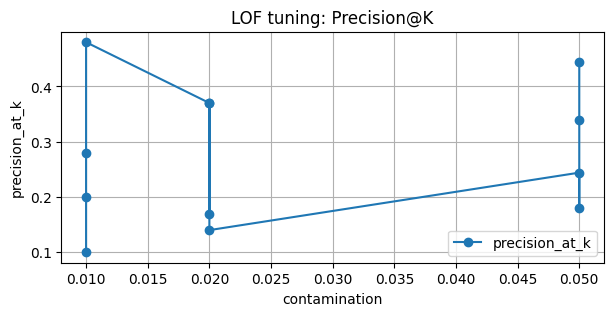

In [7]:
anomaly_runs = [run for run in runs if run.get("model_family") == "anomaly_detection" and run.get("status") == "completed"]
latest_anomaly_run = anomaly_runs[0] if anomaly_runs else None

if latest_anomaly_run:
    metrics = latest_anomaly_run.get("metrics", {})
    if_trials = pd.DataFrame(metrics.get("isolation_forest_trials", []))
    lof_trials = pd.DataFrame(metrics.get("lof_trials", []))
    selected_if = latest_anomaly_run.get("selected_params", {}).get("isolation_forest")
    selected_lof = latest_anomaly_run.get("selected_params", {}).get("lof")
    print("Selected Isolation Forest:", selected_if)
    if not if_trials.empty:
        display(
            if_trials.sort_values(by=["precision_at_k", "recall"], ascending=False, na_position="last")
            [["n_estimators", "max_samples", "contamination", "precision_at_k", "recall", "f1_proxy", "false_alarm_share"]]
            .head(10)
        )
        optional_line_plot(if_trials.sort_values("contamination"), "contamination", "precision_at_k", "Isolation Forest tuning: Precision@K")
    print("Selected LOF:", selected_lof)
    if not lof_trials.empty:
        display(
            lof_trials.sort_values(by=["precision_at_k", "recall"], ascending=False, na_position="last")
            [["n_neighbors", "contamination", "precision_at_k", "recall", "f1_proxy", "false_alarm_share"]]
            .head(10)
        )
        optional_line_plot(lof_trials.sort_values("contamination"), "contamination", "precision_at_k", "LOF tuning: Precision@K")
else:
    print("No completed anomaly detection run found yet.")


## 7. Pattern and Anomaly Examples

The following tables are useful for explanation: top reliability hotspots and recent live anomalies. These connect the models to real routes/stops that can be inspected in the dashboard.

In [8]:
if not clusters_df.empty and "dbscan_is_hotspot" in clusters_df.columns:
    hotspot_cols = [
        "route_short_name", "stop_name", "reliability_label", "prediction_coverage_ratio",
        "sample_count", "latitude", "longitude",
    ]
    hotspots = clusters_df[clusters_df["dbscan_is_hotspot"] == True]
    print("Hotspot examples from the bus-only cluster layer:", len(hotspots))
    display(hotspots[[col for col in hotspot_cols if col in hotspots.columns]].head(10))
else:
    print("No hotspot table available.")

if not anomalies_df.empty:
    anomaly_cols = [
        "bucket", "route_short_name", "stop_name", "anomaly_reason",
        "prediction_coverage_ratio", "feed_age_seconds", "isolation_forest_is_anomaly", "lof_is_anomaly",
    ]
    print("Recent anomaly examples from the bus-only anomaly layer:", len(anomalies_df))
    display(anomalies_df[[col for col in anomaly_cols if col in anomalies_df.columns]].head(10))

    if "anomaly_reason" in anomalies_df.columns:
        display(anomalies_df["anomaly_reason"].fillna("Model anomaly").value_counts().rename_axis("reason").reset_index(name="count"))
else:
    print("No live anomalies available.")


Hotspot examples from the bus-only cluster layer: 106


,route_short_name,stop_name,reliability_label,prediction_coverage_ratio,sample_count,latitude,longitude
0,52,Esikoisentie,delay_hotspot,0.982,26,60.25131,24.89707
1,52,Kaustisentie,delay_hotspot,0.982,26,60.23819,24.88278
2,56,Vaskisepäntie,delay_hotspot,0.985,26,60.22103,24.93707
3,118,Kirstin koulu,delay_hotspot,0.965,26,60.20246,24.66925
4,52,Kuopuksentie,delay_hotspot,0.985,26,60.25404,24.89732
5,52,Perhekunnantie,delay_hotspot,0.986,26,60.24874,24.89420
6,549,Valkonauhantie,delay_hotspot,0.968,26,60.22007,24.71116
7,549,Työväen Akatemia,delay_hotspot,0.979,26,60.22209,24.71463
8,52,Trumpettitie,delay_hotspot,0.990,26,60.24008,24.87360
9,52,Vanhempientie,delay_hotspot,0.985,26,60.25638,24.89763


Recent anomaly examples from the bus-only anomaly layer: 1000


,bucket,route_short_name,stop_name,anomaly_reason,prediction_coverage_ratio,feed_age_seconds,isolation_forest_is_anomaly,lof_is_anomaly
0,2026-04-27T19:00:00+00:00,171,Matinkylä (M),"extreme delay, coverage dropout",0.639,18.1,True,True
1,2026-04-27T19:00:00+00:00,434,Ruutulippu,model flagged unusual pattern,1.000,112.8,False,True
2,2026-04-27T19:00:00+00:00,246,Espoon asema,"coverage dropout, stale feed",0.857,540.9,False,True
3,2026-04-27T19:00:00+00:00,619,Kielotie,model flagged unusual pattern,1.000,112.8,False,True
4,2026-04-27T19:00:00+00:00,619,Vantaan opistotalo,model flagged unusual pattern,1.000,112.8,False,True
5,2026-04-27T19:00:00+00:00,711,Hakintie,model flagged unusual pattern,1.000,256.5,False,True
6,2026-04-27T19:00:00+00:00,711,Viikki,model flagged unusual pattern,1.000,256.5,False,True
7,2026-04-27T19:00:00+00:00,711,Koskelan varikko,model flagged unusual pattern,1.000,256.5,False,True
8,2026-04-27T19:00:00+00:00,711,Hovitie,model flagged unusual pattern,1.000,256.5,False,True
9,2026-04-27T19:00:00+00:00,711,Maarinkunnaantie,model flagged unusual pattern,1.000,256.5,False,True


,reason,count
0,model flagged unusual pattern,304
1,coverage dropout,297
2,stale feed,270
3,extreme delay,107
4,late-heavy window,10
5,"extreme delay, coverage dropout",6
6,"coverage dropout, stale feed",5
7,"late-heavy window, stale feed",1


## 8. Part 3 Conclusion

The project satisfies the Part 3 data-mining requirement using two required categories and four concrete algorithms:

- **Clustering / pattern discovery:** KMeans groups bus route-stop-hour windows into reliability profiles.
- **Clustering / hotspot discovery:** DBSCAN identifies dense bus reliability patterns and model hotspots.
- **Anomaly detection:** Isolation Forest detects unusual global feature patterns.
- **Anomaly detection:** LOF detects local outliers by comparing a window to its neighbours.

The selected models are justified using tuning tables and metrics such as Silhouette Score, Davies-Bouldin Index, Precision@K, recall, and false-alarm share. The dashboard provides operational interpretation: clusters explain recurring patterns, DBSCAN hotspots identify places to inspect, and anomaly windows form a live watchlist.

The key limitation is the amount of stored GTFS-RT history. Current results are valid for the collected bus windows, but several weeks of continuous polling would make delay-based reliability patterns stronger and more stable.
